In [1]:
import os
# Disable torch.compile/dynamo before importing torch (kept from original setup).
os.environ["TORCH_COMPILE_DISABLE"] = "1"
os.environ["TORCHDYNAMO_DISABLE"]   = "1"

import json
import math
import random
import gc
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torch.utils.checkpoint import checkpoint
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

import optuna
from optuna.samplers import NSGAIISampler
from optuna.pruners import MedianPruner


def seed_everything(seed: int, deterministic: bool = False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # During SEARCH we want speed, not bitwise reproducibility:
    # benchmark lets cuDNN autotune the fastest kernels for fixed input sizes.
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark     = not deterministic

c:\ProgramData\miniconda3\envs\lips\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
class LipReadingDataset(Dataset):
    def __init__(self, cache_dir, split="train", is_training=True,
                 num_classes=None, fixed_labels=None, time_mask_max: int = 0):
        self.is_training = is_training
        self.time_mask_max = time_mask_max
        self.samples, self.labels = self._load_split(
            Path(cache_dir), split, num_classes, fixed_labels)
        self.label2idx = {w: i for i, w in enumerate(self.labels)}

    def _load_split(self, cache_root, split, num_classes, fixed_labels):
        raw, labels_seen = [], set()
        for word_folder in cache_root.iterdir():
            if not word_folder.is_dir():
                continue
            split_path = word_folder / split
            if not split_path.exists():
                continue
            word = word_folder.name.upper()
            for npy in split_path.glob("*.npy"):
                raw.append((npy, word))
                labels_seen.add(word)

        if fixed_labels is not None:
            sorted_labels = fixed_labels
        else:
            sorted_labels = sorted(labels_seen)
            if num_classes:
                sorted_labels = sorted_labels[:num_classes]

        label2idx = {w: i for i, w in enumerate(sorted_labels)}
        filtered = [(p, label2idx[w]) for p, w in raw if w in label2idx]
        print(f"[{split}] {len(filtered)} samples, {len(sorted_labels)} classes.")
        return filtered, sorted_labels

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        npy_path, label = self.samples[idx]
        try:
            arr = np.load(str(npy_path))
        except Exception:
            arr = np.zeros((1, Config.PRE_CROP_SIZE, Config.PRE_CROP_SIZE), dtype=np.uint8)

        real_count = min(len(arr), Config.MAX_FRAMES)
        arr = arr[:real_count]
        frames = torch.from_numpy(arr).float().div(255.0).unsqueeze(1)

        word_boundaries = torch.zeros(Config.MAX_FRAMES, 1)
        word_boundaries[:real_count] = 1.0

        if self.is_training and self.time_mask_max > 0:
            max_mask = min(self.time_mask_max, real_count)
            frames = apply_time_masking(frames, max_mask=max_mask)

        pad_len = Config.MAX_FRAMES - real_count
        if pad_len > 0:
            pad = torch.zeros(pad_len, 1, Config.PRE_CROP_SIZE, Config.PRE_CROP_SIZE)
            frames = torch.cat([frames, pad], dim=0)

        if self.is_training:
            h, w = Config.PRE_CROP_SIZE, Config.PRE_CROP_SIZE
            th, tw = Config.FRAME_SIZE, Config.FRAME_SIZE
            i = random.randint(0, h - th)
            j = random.randint(0, w - tw)
            frames = TF.crop(frames, i, j, th, tw)
            if random.random() < 0.5:
                frames = TF.hflip(frames)
        else:
            frames = TF.center_crop(frames, (Config.FRAME_SIZE, Config.FRAME_SIZE))

        return frames, word_boundaries, label

In [2]:
class Chomp1d(nn.Module):
    def __init__(self, chomp_size, symm_chomp):
        super(Chomp1d, self).__init__()
        self.chomp_size = chomp_size
        self.symm_chomp = symm_chomp
        if self.symm_chomp:
            assert self.chomp_size % 2 == 0, "If symmetric chomp, chomp size needs to be even"
    def forward(self, x):
        if self.chomp_size == 0:
            return x
        if self.symm_chomp:
            return x[:, :, self.chomp_size//2:-self.chomp_size//2].contiguous()
        else:
            return x[:, :, :-self.chomp_size].contiguous()
        

class ConvBatchChompRelu(nn.Module):
    def __init__(self, n_inputs, n_outputs, kernel_size, stride, dilation, padding, relu_type, dwpw=False):
        super(ConvBatchChompRelu, self).__init__()
        self.dwpw = dwpw
        if dwpw:
            self.conv = nn.Sequential(
                # -- dw
                nn.Conv1d( n_inputs, n_inputs, kernel_size, stride=stride,
                           padding=padding, dilation=dilation, groups=n_inputs, bias=False),
                nn.BatchNorm1d(n_inputs),
                Chomp1d(padding, True),
                nn.PReLU(num_parameters=n_inputs) if relu_type == 'prelu' else nn.ReLU(inplace=True),
                # -- pw
                nn.Conv1d( n_inputs, n_outputs, 1, 1, 0, bias=False),
                nn.BatchNorm1d(n_outputs),
                nn.PReLU(num_parameters=n_outputs) if relu_type == 'prelu' else nn.ReLU(inplace=True)
            )
        else:
            self.conv = nn.Conv1d(n_inputs, n_outputs, kernel_size,
                                               stride=stride, padding=padding, dilation=dilation)
            self.batchnorm = nn.BatchNorm1d(n_outputs)
            self.chomp = Chomp1d(padding,True)
            self.non_lin = nn.PReLU(num_parameters=n_outputs) if relu_type == 'prelu' else Swish() if relu_type == 'swish' else nn.ReLU()

    def forward(self, x):
        if self.dwpw:
            return self.conv(x)
        else:
            out = self.conv( x )
            out = self.batchnorm( out )
            out = self.chomp( out )
            return self.non_lin( out )


        
# --------- MULTI-BRANCH VERSION ---------------
class MultibranchTemporalBlock(nn.Module):
    def __init__(self, n_inputs, n_outputs, kernel_sizes, stride, dilation, padding, dropout=0.2, 
                 relu_type = 'relu', dwpw=False):
        super(MultibranchTemporalBlock, self).__init__()
        
        self.kernel_sizes = kernel_sizes
        self.num_kernels = len( kernel_sizes )
        self.n_outputs_branch = n_outputs // self.num_kernels
        assert n_outputs % self.num_kernels == 0, "Number of output channels needs to be divisible by number of kernels"



        for k_idx,k in enumerate( self.kernel_sizes ):
            cbcr = ConvBatchChompRelu( n_inputs, self.n_outputs_branch, k, stride, dilation, padding[k_idx], relu_type, dwpw=dwpw)
            setattr( self,'cbcr0_{}'.format(k_idx), cbcr )
        self.dropout0 = nn.Dropout(dropout)
        
        for k_idx,k in enumerate( self.kernel_sizes ):
            cbcr = ConvBatchChompRelu( n_outputs, self.n_outputs_branch, k, stride, dilation, padding[k_idx], relu_type, dwpw=dwpw)
            setattr( self,'cbcr1_{}'.format(k_idx), cbcr )
        self.dropout1 = nn.Dropout(dropout)

        # downsample?
        self.downsample = nn.Conv1d(n_inputs, n_outputs, 1) if (n_inputs//self.num_kernels) != n_outputs else None
        
        # final relu
        if relu_type == 'relu':
            self.relu_final = nn.ReLU()
        elif relu_type == 'prelu':
            self.relu_final = nn.PReLU(num_parameters=n_outputs)
        elif relu_type == 'swish':
            self.relu_final = Swish()

    def forward(self, x):

        # first multi-branch set of convolutions
        outputs = []
        for k_idx in range( self.num_kernels ):
            branch_convs = getattr(self,'cbcr0_{}'.format(k_idx))
            outputs.append( branch_convs(x) )
        out0 = torch.cat(outputs, 1)
        out0 = self.dropout0( out0 )

        # second multi-branch set of convolutions
        outputs = []
        for k_idx in range( self.num_kernels ):
            branch_convs = getattr(self,'cbcr1_{}'.format(k_idx))
            outputs.append( branch_convs(out0) )
        out1 = torch.cat(outputs, 1)
        out1 = self.dropout1( out1 )
                
        # downsample?
        res = x if self.downsample is None else self.downsample(x)

        return self.relu_final(out1 + res)

class MultibranchTemporalConvNet(nn.Module):
    def __init__(self, num_inputs, num_channels, tcn_options, dropout=0.2, relu_type='relu', dwpw=False):
        super(MultibranchTemporalConvNet, self).__init__()

        self.ksizes = tcn_options['kernel_size']

        layers = []
        num_levels = len(num_channels)
        for i in range(num_levels):
            dilation_size = 2 ** i
            in_channels = num_inputs if i == 0 else num_channels[i-1]
            out_channels = num_channels[i]


            padding = [ (s-1)*dilation_size for s in self.ksizes]            
            layers.append( MultibranchTemporalBlock( in_channels, out_channels, self.ksizes, 
                stride=1, dilation=dilation_size, padding = padding, dropout=dropout, relu_type = relu_type,
                dwpw=dwpw) )

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)        
# --------------------------------


# --------------- STANDARD VERSION (SINGLE BRANCH) ------------------------
class TemporalBlock(nn.Module):
    def __init__(self, n_inputs, n_outputs, kernel_size, stride, dilation, padding, dropout=0.2, 
                 symm_chomp = False, no_padding = False, relu_type = 'relu', dwpw=False):
        super(TemporalBlock, self).__init__()
        
        self.no_padding = no_padding
        if self.no_padding:
            downsample_chomp_size = 2*padding-4
            padding = 1 # hack-ish thing so that we can use 3 layers

        if dwpw:
            self.net = nn.Sequential(
                # -- first conv set within block
                # -- dw
                nn.Conv1d( n_inputs, n_inputs, kernel_size, stride=stride,
                           padding=padding, dilation=dilation, groups=n_inputs, bias=False),
                nn.BatchNorm1d(n_inputs),
                Chomp1d(padding, True),
                nn.PReLU(num_parameters=n_inputs) if relu_type == 'prelu' else Swish() if relu_type == 'swish' else nn.ReLU(inplace=True),
                # -- pw
                nn.Conv1d( n_inputs, n_outputs, 1, 1, 0, bias=False),
                nn.BatchNorm1d(n_outputs),
                nn.PReLU(num_parameters=n_outputs) if relu_type == 'prelu' else Swish() if relu_type == 'swish' else nn.ReLU(inplace=True),
                nn.Dropout(dropout),
                # -- second conv set within block
                # -- dw
                nn.Conv1d( n_outputs, n_outputs, kernel_size, stride=stride,
                           padding=padding, dilation=dilation, groups=n_outputs, bias=False),
                nn.BatchNorm1d(n_outputs),
                Chomp1d(padding, True),
                nn.PReLU(num_parameters=n_outputs) if relu_type == 'prelu' else Swish() if relu_type == 'swish' else nn.ReLU(inplace=True),
                # -- pw
                nn.Conv1d( n_outputs, n_outputs, 1, 1, 0, bias=False),
                nn.BatchNorm1d(n_outputs),
                nn.PReLU(num_parameters=n_outputs) if relu_type == 'prelu' else Swish() if relu_type == 'swish' else nn.ReLU(inplace=True),
                nn.Dropout(dropout),
            )
        else:
            self.conv1 = nn.Conv1d(n_inputs, n_outputs, kernel_size,
                                   stride=stride, padding=padding, dilation=dilation)
            self.batchnorm1 = nn.BatchNorm1d(n_outputs)
            self.chomp1 = Chomp1d(padding,symm_chomp)  if not self.no_padding else None
            if relu_type == 'relu':
                self.relu1 = nn.ReLU()
            elif relu_type == 'prelu':
                self.relu1 = nn.PReLU(num_parameters=n_outputs)
            elif relu_type == 'swish':
                self.relu1 = Swish()
            self.dropout1 = nn.Dropout(dropout)
            
            self.conv2 = nn.Conv1d(n_outputs, n_outputs, kernel_size,
                                               stride=stride, padding=padding, dilation=dilation)
            self.batchnorm2 = nn.BatchNorm1d(n_outputs)
            self.chomp2 = Chomp1d(padding,symm_chomp) if not self.no_padding else None
            if relu_type == 'relu':
                self.relu2 = nn.ReLU()
            elif relu_type == 'prelu':
                self.relu2 = nn.PReLU(num_parameters=n_outputs)
            elif relu_type == 'swish':
                self.relu2 = Swish()
            self.dropout2 = nn.Dropout(dropout)
            
      
            if self.no_padding:
                self.net = nn.Sequential(self.conv1, self.batchnorm1, self.relu1, self.dropout1,
                                         self.conv2, self.batchnorm2, self.relu2, self.dropout2)
            else:
                self.net = nn.Sequential(self.conv1, self.batchnorm1, self.chomp1, self.relu1, self.dropout1,
                                         self.conv2, self.batchnorm2, self.chomp2, self.relu2, self.dropout2)

        self.downsample = nn.Conv1d(n_inputs, n_outputs, 1) if n_inputs != n_outputs else None
        if self.no_padding:
            self.downsample_chomp = Chomp1d(downsample_chomp_size,True)
        if relu_type == 'relu':
            self.relu = nn.ReLU()
        elif relu_type == 'prelu':
            self.relu = nn.PReLU(num_parameters=n_outputs)
        elif relu_type == 'swish':
            self.relu = Swish()

    def forward(self, x):
        out = self.net(x)
        if self.no_padding:
            x = self.downsample_chomp(x)
        res = x if self.downsample is None else self.downsample(x)
        return self.relu(out + res)


class TemporalConvNet(nn.Module):
    def __init__(self, num_inputs, num_channels, tcn_options, dropout=0.2, relu_type='relu', dwpw=False):
        super(TemporalConvNet, self).__init__()
        self.ksize = tcn_options['kernel_size'][0] if isinstance(tcn_options['kernel_size'], list) else tcn_options['kernel_size']
        layers = []
        num_levels = len(num_channels)
        for i in range(num_levels):
            dilation_size = 2 ** i
            in_channels = num_inputs if i == 0 else num_channels[i-1]
            out_channels = num_channels[i]
            layers.append( TemporalBlock(in_channels, out_channels, self.ksize, stride=1, dilation=dilation_size,
                                     padding=(self.ksize-1) * dilation_size, dropout=dropout, symm_chomp = True,
                                     no_padding = False, relu_type=relu_type, dwpw=dwpw) )
            
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [4]:
class SELayer(nn.Module):
    def __init__(self, channel, reduction=2):
        super(SELayer, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Sequential(
            nn.Linear(channel, channel // reduction, bias=False),
            Swish(),
            nn.Linear(channel // reduction, channel, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, T = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1)
        return x * y.expand_as(x)

In [5]:
def conv3x3(in_planes, out_planes, stride=1):
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride,
                     padding=1, bias=False)


def downsample_basic_block( inplanes, outplanes, stride ):
    return  nn.Sequential(
                nn.Conv2d(inplanes, outplanes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(outplanes),
            )

def downsample_basic_block_v2( inplanes, outplanes, stride ):
    return  nn.Sequential(
                nn.AvgPool2d(kernel_size=stride, stride=stride, ceil_mode=True, count_include_pad=False),
                nn.Conv2d(inplanes, outplanes, kernel_size=1, stride=1, bias=False),
                nn.BatchNorm2d(outplanes),
            )



class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, inplanes, planes, stride=1, downsample=None, relu_type = 'prelu' ):
        super(BasicBlock, self).__init__()

        assert relu_type in ['relu','prelu', 'swish']

        self.conv1 = conv3x3(inplanes, planes, stride)
        self.bn1 = nn.BatchNorm2d(planes)

        # type of ReLU is an input option
        if relu_type == 'relu':
            self.relu1 = nn.ReLU(inplace=True)
            self.relu2 = nn.ReLU(inplace=True)
        elif relu_type == 'prelu':
            self.relu1 = nn.PReLU(num_parameters=planes)
            self.relu2 = nn.PReLU(num_parameters=planes)
        elif relu_type == 'swish':
            self.relu1 = Swish()
            self.relu2 = Swish()
        else:
            raise Exception('relu type not implemented')
        # --------

        self.conv2 = conv3x3(planes, planes)
        self.bn2 = nn.BatchNorm2d(planes)

        self.downsample = downsample
        self.stride = stride

    def forward(self, x):
        residual = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu1(out)
        out = self.conv2(out)
        out = self.bn2(out)
        if self.downsample is not None:
            residual = self.downsample(x)

        out += residual
        out = self.relu2(out)

        return out


class ResNet(nn.Module):

    def __init__(self, block, layers, num_classes=1000, relu_type = 'relu', gamma_zero = False, avg_pool_downsample = False):
        self.inplanes = 64
        self.relu_type = relu_type
        self.gamma_zero = gamma_zero
        self.downsample_block = downsample_basic_block_v2 if avg_pool_downsample else downsample_basic_block

        super(ResNet, self).__init__()
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d(1)

        # default init
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                n = m.kernel_size[0] * m.kernel_size[1] * m.out_channels
                m.weight.data.normal_(0, math.sqrt(2. / n))
            elif isinstance(m, nn.BatchNorm2d):
                m.weight.data.fill_(1)
                m.bias.data.zero_()
                #nn.init.ones_(m.weight)
                #nn.init.zeros_(m.bias)

        if self.gamma_zero:
            for m in self.modules():
                if isinstance(m, BasicBlock ):
                    m.bn2.weight.data.zero_()

    def _make_layer(self, block, planes, blocks, stride=1):


        downsample = None
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = self.downsample_block( inplanes = self.inplanes,
                                                 outplanes = planes * block.expansion,
                                                 stride = stride )

        layers = []
        layers.append(block(self.inplanes, planes, stride, downsample, relu_type = self.relu_type))
        self.inplanes = planes * block.expansion
        for i in range(1, blocks):
            layers.append(block(self.inplanes, planes, relu_type = self.relu_type))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)
        return x

In [6]:
class Swish(nn.Module):
    """Construct an Swish object."""

    def forward(self, x):
        """Return Swich activation function."""
        return x * torch.sigmoid(x)




class Chomp1d(nn.Module):
    def __init__(self, chomp_size, symm_chomp):
        super(Chomp1d, self).__init__()
        self.chomp_size = chomp_size
        self.symm_chomp = symm_chomp
        if self.symm_chomp:
            assert self.chomp_size % 2 == 0, "If symmetric chomp, chomp size needs to be even"
    def forward(self, x):
        if self.chomp_size == 0:
            return x
        if self.symm_chomp:
            return x[:, :, self.chomp_size//2:-self.chomp_size//2].contiguous()
        else:
            return x[:, :, :-self.chomp_size].contiguous()


class TemporalConvLayer(nn.Module):
    def __init__(self, n_inputs, n_outputs, kernel_size, stride, dilation, padding, relu_type):
        super(TemporalConvLayer, self).__init__()
        self.net = nn.Sequential(
                nn.Conv1d( n_inputs, n_outputs, kernel_size,
                           stride=stride, padding=padding, dilation=dilation),
                nn.BatchNorm1d(n_outputs),
                Chomp1d(padding, True),
                nn.PReLU(num_parameters=n_outputs) if relu_type == 'prelu' else Swish() if relu_type == 'swish' else nn.ReLU(),)

    def forward(self, x):
        return self.net(x)


class _ConvBatchChompRelu(nn.Module):
    def __init__(self, n_inputs, n_outputs, kernel_size_set, stride, dilation, dropout, relu_type, se_module=False):
        super(_ConvBatchChompRelu, self).__init__()

        self.num_kernels = len( kernel_size_set )
        self.n_outputs_branch = n_outputs // self.num_kernels
        assert n_outputs % self.num_kernels == 0, "Number of output channels needs to be divisible by number of kernels"

        for k_idx,k in enumerate( kernel_size_set ):
            if se_module:
                setattr( self, 'cbcr0_se_{}'.format(k_idx), SELayer( n_inputs, reduction=16))
            cbcr = TemporalConvLayer( n_inputs, self.n_outputs_branch, k, stride, dilation, (k-1)*dilation, relu_type)
            setattr( self,'cbcr0_{}'.format(k_idx), cbcr )
        self.dropout0 = nn.Dropout(dropout)
        for k_idx,k in enumerate( kernel_size_set ):
            cbcr = TemporalConvLayer( n_outputs, self.n_outputs_branch, k, stride, dilation, (k-1)*dilation, relu_type)
            setattr( self,'cbcr1_{}'.format(k_idx), cbcr )
        self.dropout1 = nn.Dropout(dropout)

        self.se_module = se_module
        self.downsample = nn.Conv1d(n_inputs, n_outputs, 1) if n_inputs != n_outputs else None

        # final relu
        if relu_type == 'relu':
            self.relu_final = nn.ReLU()
        elif relu_type == 'prelu':
            self.relu_final = nn.PReLU(num_parameters=n_outputs)
        elif relu_type == 'swish':
            self.relu_final = Swish()

    def bn_function(self, inputs):
        # type: (List[Tensor]) -> Tensor
        x = torch.cat(inputs, 1)
        outputs = []
        for k_idx in range( self.num_kernels ):
            if self.se_module:
                branch_se = getattr(self,'cbcr0_se_{}'.format(k_idx))
            branch_convs = getattr(self,'cbcr0_{}'.format(k_idx))
            if self.se_module:
                outputs.append( branch_convs(branch_se(x)))
            else:
                outputs.append( branch_convs(x) )
        out0 = torch.cat(outputs, 1)
        out0 = self.dropout0( out0 )
        # second multi-branch set of convolutions
        outputs = []
        for k_idx in range( self.num_kernels ):
            branch_convs = getattr(self,'cbcr1_{}'.format(k_idx))
            outputs.append( branch_convs(out0) )
        out1 = torch.cat(outputs, 1)
        out1 = self.dropout1( out1 )
        # downsample?
        res = x if self.downsample is None else self.downsample(x)
        return self.relu_final(out1 + res)

    def forward(self, input):
        if isinstance(input, torch.Tensor):
            prev_features = [input]
        else:
            prev_features = input
        bottleneck_output = self.bn_function(prev_features)
        return bottleneck_output


class _DenseBlock(nn.ModuleDict):
    _version = 2

    def __init__( self, num_layers, num_input_features, growth_rate,
                  kernel_size_set, dilation_size_set,
                  dropout, relu_type, squeeze_excitation,
                  ):
        super(_DenseBlock, self).__init__()
        for i in range(num_layers):
            dilation_size = dilation_size_set[i%len(dilation_size_set)]
            layer = _ConvBatchChompRelu(
                n_inputs=num_input_features + i * growth_rate,
                n_outputs=growth_rate,
                kernel_size_set=kernel_size_set,
                stride=1,
                dilation=dilation_size,
                dropout=dropout,
                relu_type=relu_type,
                se_module=squeeze_excitation,
                )

            self.add_module('denselayer%d' % (i + 1), layer)

    def forward(self, init_features):
        features = [init_features]
        for name, layer in self.items():
            new_features = layer(features)
            features.append(new_features)
        return torch.cat(features, 1)


class _Transition(nn.Sequential):
    def __init__(self, num_input_features, num_output_features, relu_type):
        super(_Transition, self).__init__()
        self.add_module('conv', nn.Conv1d(num_input_features, num_output_features,
                                          kernel_size=1, stride=1, bias=False))
        self.add_module('norm', nn.BatchNorm1d(num_output_features))
        if relu_type == 'relu':
            self.add_module('relu', nn.ReLU())
        elif relu_type == 'prelu':
            self.add_module('prelu', nn.PReLU(num_parameters=num_output_features))
        elif relu_type == 'swish':
            self.add_module('swish', Swish())


class DenseTemporalConvNet(nn.Module):
    def __init__(self, block_config, growth_rate_set, input_size, reduced_size,
                 kernel_size_set, dilation_size_set,
                 dropout=0.2, relu_type='prelu',
                 squeeze_excitation=False,
                 ):
        super(DenseTemporalConvNet, self).__init__()
        self.features = nn.Sequential(OrderedDict([]))

        trans = _Transition(num_input_features=input_size,
                            num_output_features=reduced_size,
                            relu_type='prelu')
        self.features.add_module('transition%d' % (0), trans)
        num_features = reduced_size

        for i, num_layers in enumerate(block_config):

            block = _DenseBlock(
                num_layers=num_layers,
                num_input_features=num_features,
                growth_rate=growth_rate_set[i],
                kernel_size_set=kernel_size_set,
                dilation_size_set=dilation_size_set,
                dropout=dropout,
                relu_type=relu_type,
                squeeze_excitation=squeeze_excitation,
                )
            self.features.add_module('denseblock%d' % (i + 1), block)
            num_features = num_features + num_layers * growth_rate_set[i]

            if i != len(block_config) - 1:
                trans = _Transition(num_input_features=num_features,
                                    num_output_features=reduced_size,
                                    relu_type=relu_type)
                self.features.add_module('transition%d' % (i + 1), trans)
                num_features = reduced_size

        # Final batch norm
        self.features.add_module('norm5', nn.BatchNorm1d(num_features))


    def forward(self, x):
        features = self.features(x)
        return features

In [7]:
class Lipreading(nn.Module):
    """ResNet-18 frontend -> DC-TCN -> linear classifier. Input (B, T, 1, 88, 88)."""

    def __init__(self, num_classes=500, relu_type='swish', densetcn_options=None,
                 grad_checkpoint=False):
        super().__init__()
        self.grad_checkpoint = grad_checkpoint

        densetcn_options = densetcn_options or dict(
            block_config       = [3, 3, 3, 3],
            growth_rate_set    = [384, 384, 384, 384],
            reduced_size       = 512,
            kernel_size_set    = [3, 5, 7],
            dilation_size_set  = [1, 2, 5],
            dropout            = 0.2,
            squeeze_excitation = False,
        )

        relu_map = {'relu':  nn.ReLU(inplace=True),
                    'prelu': nn.PReLU(64),
                    'swish': nn.SiLU(inplace=True)}
        frontend_relu = relu_map[relu_type]

        self.frontend3D = nn.Sequential(
            nn.Conv3d(1, 64, kernel_size=(5, 7, 7),
                      stride=(1, 2, 2), padding=(2, 3, 3), bias=False),
            nn.BatchNorm3d(64),
            frontend_relu,
            nn.MaxPool3d(kernel_size=(1, 3, 3), stride=(1, 2, 2), padding=(0, 1, 1)),
        )

        self.trunk = ResNet(BasicBlock, [2, 2, 2, 2], relu_type=relu_type)

        self.tcn = DenseTemporalConvNet(
            block_config       = densetcn_options['block_config'],
            growth_rate_set    = densetcn_options['growth_rate_set'],
            input_size         = 512,
            reduced_size       = densetcn_options['reduced_size'],
            kernel_size_set    = densetcn_options['kernel_size_set'],
            dilation_size_set  = densetcn_options['dilation_size_set'],
            dropout            = densetcn_options['dropout'],
            relu_type          = relu_type,
            squeeze_excitation = densetcn_options['squeeze_excitation'],
        )

        tcn_out = (densetcn_options['reduced_size']
                   + densetcn_options['block_config'][-1]
                   * densetcn_options['growth_rate_set'][-1])
        self.classifier = nn.Linear(tcn_out, num_classes)

    def forward(self, x, word_bounds=None):
        B, T = x.size(0), x.size(1)
        x = x.permute(0, 2, 1, 3, 4).contiguous()           # (B, 1, T, H, W)
        x = self.frontend3D(x)                              # (B, 64, T', 22, 22)

        Tp = x.size(2)
        x = x.transpose(1, 2).contiguous()
        x = x.view(B * Tp, 64, x.size(3), x.size(4))

        # Gradient checkpointing on the two heavy submodules saves a lot of VRAM.
        if self.grad_checkpoint and self.training:
            x = checkpoint(self.trunk, x, use_reentrant=False)    # (B*T', 512)
        else:
            x = self.trunk(x)

        x = x.view(B, Tp, -1).transpose(1, 2).contiguous()  # (B, 512, T')

        if self.grad_checkpoint and self.training:
            x = checkpoint(self.tcn, x, use_reentrant=False)      # (B, tcn_out, T')
        else:
            x = self.tcn(x)

        if word_bounds is not None:
            wb = word_bounds
            if wb.dim() == 3:
                wb = wb.squeeze(-1)
            if wb.size(1) != Tp:
                if wb.size(1) > Tp:
                    wb = wb[:, :Tp]
                else:
                    pad = Tp - wb.size(1)
                    wb = torch.cat([wb, wb.new_zeros(wb.size(0), pad)], dim=1)
            wb = wb.unsqueeze(1)
            x = x * wb

        x = x.mean(dim=-1)
        return self.classifier(x)

In [8]:
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    total_loss, correct1, total = 0.0, 0, 0
    for clips, word_bounds, labels in tqdm(loader, desc="Eval ", leave=False):
        clips       = clips.to(device, non_blocking=True)
        word_bounds = word_bounds.to(device, non_blocking=True)
        labels      = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=Config.AMP):
            logits = model(clips, word_bounds)
            loss   = F.cross_entropy(logits, labels)
        total_loss += loss.item() * clips.size(0)
        total      += clips.size(0)
        correct1   += (logits.argmax(1) == labels).sum().item()
    return total_loss / total, correct1 / total

In [ ]:
# =====================================================================
# *** CHANGE VARIANT HERE to switch between small / medium / large ***
# =====================================================================
VARIANT = "small"      # choose: "small" | "medium" | "large"

VARIANT_INFO = {
    "small":  dict(suffix="s", max_frames=30,
                   ckpt=r"C:\Users\Andreea Andriciuc\Downloads\best_resnet_dctcn_small.pth"),
    "medium": dict(suffix="m", max_frames=40,
                   ckpt=r"C:\Users\Andreea Andriciuc\Downloads\best_resnet_dctcn_medium.pth"),
    "large":  dict(suffix="l", max_frames=60,
                   ckpt=r"C:\Users\Andreea Andriciuc\Downloads\best_resnet_dctcn_large.pth"),
}

class Config:
    # Kaggle dataset mount. If this is wrong, the next cell auto-detects it.
    CACHE_DIR     = r"C:\Users\Andreea Andriciuc\Downloads\lipropod_cache\lipropod_cache"
    PRE_CROP_SIZE = 96
    FRAME_SIZE    = 88
    NUM_CLASSES   = 75
    MAX_FRAMES    = VARIANT_INFO[VARIANT]["max_frames"]

    # Effective batch = BATCH_SIZE * ACCUM_STEPS = 32 (matches the search).
    # Kaggle T4 has 16 GB, so gradient checkpointing is off for speed. If the
    # large variant OOMs: set BATCH_SIZE=16, ACCUM_STEPS=2, or GRAD_CHECKPOINT=True.
    BATCH_SIZE      = 32
    ACCUM_STEPS     = 1
    NUM_WORKERS     = 0
    GRAD_CHECKPOINT = False

    EPOCHS    = 80
    PATIENCE  = 10
    SELECT_BY = "val_acc"          # "val_acc" or "val_loss"

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    AMP    = torch.cuda.is_available()
    SEED   = 420


# Best parameters exported by each Optuna search.
BEST_PARAMS_JSON = {
"small": r'''
{
  "study_name": "resnet_dctcn_lipro_small_v1",
  "best_by_val_acc": {
    "trial_number": 11,
    "val_loss": 1.9664103978495215,
    "val_acc": 0.47262094630515683,
    "params": {
      "lr": 0.00010283904375026542,
      "weight_decay": 2.2860831916972384e-05,
      "label_smoothing": 0.05339645277799241,
      "time_mask_max": 1,
      "mixup_prob": 0.18133906912000497,
      "mixup_alpha": 0.5408099624788877,
      "grad_clip": 2.4100748316692604,
      "dcn_block_config": "3,3,3,3",
      "dcn_growth_rate_set": "192,192,192,192",
      "dcn_kernel_size_set": "3,3,3",
      "dcn_dilation_size_set": "1,1,1",
      "dcn_reduced_size": 256,
      "dcn_dropout": 0.021300565532411553,
      "dcn_squeeze_excitation": false,
      "dcn_relu_type": "swish"
    }
  },
  "best_by_val_loss": {
    "trial_number": 11,
    "val_loss": 1.9664103978495215,
    "val_acc": 0.47262094630515683,
    "params": {
      "lr": 0.00010283904375026542,
      "weight_decay": 2.2860831916972384e-05,
      "label_smoothing": 0.05339645277799241,
      "time_mask_max": 1,
      "mixup_prob": 0.18133906912000497,
      "mixup_alpha": 0.5408099624788877,
      "grad_clip": 2.4100748316692604,
      "dcn_block_config": "3,3,3,3",
      "dcn_growth_rate_set": "192,192,192,192",
      "dcn_kernel_size_set": "3,3,3",
      "dcn_dilation_size_set": "1,1,1",
      "dcn_reduced_size": 256,
      "dcn_dropout": 0.021300565532411553,
      "dcn_squeeze_excitation": false,
      "dcn_relu_type": "swish"
    }
  }
}
''',
"medium": r'''
{
  "study_name": "resnet_dctcn_lipro_medium_v4",
  "best_by_val_acc": {
    "trial_number": 12,
    "val_loss": 1.8499881821105502,
    "val_acc": 0.5055940330314331,
    "params": {
      "lr": 0.00010283904375026542,
      "weight_decay": 3.4956121598058678e-06,
      "label_smoothing": 0.02241217713822872,
      "time_mask_max": 1,
      "mixup_prob": 0.17110563357793807,
      "mixup_alpha": 0.27971547971553434,
      "grad_clip": 4.262739011225239,
      "dcn_block_config": "3,3,3,3",
      "dcn_growth_rate_set": "192,192,192,192",
      "dcn_kernel_size_set": "3,3,3",
      "dcn_dilation_size_set": "1,1,1",
      "dcn_reduced_size": 256,
      "dcn_dropout": 0.20294340405277717,
      "dcn_squeeze_excitation": false,
      "dcn_relu_type": "relu"
    }
  },
  "best_by_val_loss": {
    "trial_number": 12,
    "val_loss": 1.8499881821105502,
    "val_acc": 0.5055940330314331,
    "params": {
      "lr": 0.00010283904375026542,
      "weight_decay": 3.4956121598058678e-06,
      "label_smoothing": 0.02241217713822872,
      "time_mask_max": 1,
      "mixup_prob": 0.17110563357793807,
      "mixup_alpha": 0.27971547971553434,
      "grad_clip": 4.262739011225239,
      "dcn_block_config": "3,3,3,3",
      "dcn_growth_rate_set": "192,192,192,192",
      "dcn_kernel_size_set": "3,3,3",
      "dcn_dilation_size_set": "1,1,1",
      "dcn_reduced_size": 256,
      "dcn_dropout": 0.20294340405277717,
      "dcn_squeeze_excitation": false,
      "dcn_relu_type": "relu"
    }
  }
}
''',
"large": r'''
  {
  "study_name": "resnet_dctcn_lipro_large_v1",
  "best_by_val_acc": {
    "trial_number": 16,
    "val_loss": 2.005148374048869,
    "val_acc": 0.4912,
    "params": {
      "lr": 3.437739314870306e-05,
      "weight_decay": 0.00017165231458107053,
      "label_smoothing": 0.03847189999014027,
      "time_mask_max": 1,
      "mixup_prob": 0.43408323964268924,
      "mixup_alpha": 0.5408099624788877,
      "grad_clip": 2.4100748316692604,
      "dcn_block_config": "3,3,3,3",
      "dcn_growth_rate_set": "192,192,192,192",
      "dcn_kernel_size_set": "3,5,7",
      "dcn_dilation_size_set": "1,2,5",
      "dcn_reduced_size": 256,
      "dcn_dropout": 0.021300565532411553,
      "dcn_squeeze_excitation": true,
      "dcn_relu_type": "prelu"
    }
  },
  "best_by_val_loss": {
    "trial_number": 0,
    "val_loss": 1.9485072704315185,
    "val_acc": 0.4901333333333333,
    "params": {
      "lr": 3.437739314870306e-05,
      "weight_decay": 2.2860831916972384e-05,
      "label_smoothing": 0.05339645277799241,
      "time_mask_max": 1,
      "mixup_prob": 0.43408323964268924,
      "mixup_alpha": 0.5408099624788877,
      "grad_clip": 2.4100748316692604,
      "dcn_block_config": "3,3,3,3",
      "dcn_growth_rate_set": "192,192,192,192",
      "dcn_kernel_size_set": "3,5,7",
      "dcn_dilation_size_set": "1,1,1",
      "dcn_reduced_size": 256,
      "dcn_dropout": 0.021300565532411553,
      "dcn_squeeze_excitation": false,
      "dcn_relu_type": "prelu"
    }
  }
}
'''
}

In [10]:
# =====================================================================
# Load searched hyperparameters for VARIANT + build the data loaders
# =====================================================================
import matplotlib.pyplot as plt


def parse_list(s):
    return [int(x) for x in str(s).split(",")]


def params_from_blob(blob, select_by):
    key = "best_by_val_acc" if select_by == "val_acc" else "best_by_val_loss"
    p = blob[key]["params"]
    densetcn_options = dict(
        block_config       = parse_list(p["dcn_block_config"]),
        growth_rate_set    = parse_list(p["dcn_growth_rate_set"]),
        reduced_size       = int(p["dcn_reduced_size"]),
        kernel_size_set    = parse_list(p["dcn_kernel_size_set"]),
        dilation_size_set  = parse_list(p["dcn_dilation_size_set"]),
        dropout            = float(p["dcn_dropout"]),
        squeeze_excitation = bool(p["dcn_squeeze_excitation"]),
    )
    opt = dict(
        lr              = float(p["lr"]),
        weight_decay    = float(p["weight_decay"]),
        label_smoothing = float(p["label_smoothing"]),
        grad_clip       = float(p["grad_clip"]),
        mixup_prob      = float(p["mixup_prob"]),
        mixup_alpha     = float(p["mixup_alpha"]),
        time_mask_max   = int(p["time_mask_max"]),
        relu_type       = p["dcn_relu_type"],
    )
    return opt, densetcn_options, blob[key]["trial_number"]


@torch.no_grad()
def evaluate_topk(model, loader, device, amp, topk=5):
    model.eval()
    total, c1, ck, loss_sum = 0, 0, 0, 0.0
    for clips, word_bounds, labels in tqdm(loader, desc="Test ", leave=False):
        clips       = clips.to(device, non_blocking=True)
        word_bounds = word_bounds.to(device, non_blocking=True)
        labels      = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=amp):
            logits = model(clips, word_bounds)
            loss   = F.cross_entropy(logits, labels)
        loss_sum += loss.item() * clips.size(0)
        total    += clips.size(0)
        c1 += (logits.argmax(1) == labels).sum().item()
        k = min(topk, logits.size(1))
        _, tk = logits.topk(k, dim=1)
        ck += (tk == labels.unsqueeze(1)).sum().item()
    return loss_sum / total, c1 / total, ck / total


def resolve_cache_dir(default):
    if Path(default).exists():
        return default
    for c in Path("/kaggle/input").rglob("lipropod_cache"):
        if c.is_dir():
            print(f"[cache] default path not found; using {c}")
            return str(c)
    raise FileNotFoundError(
        "Could not locate 'lipropod_cache' under /kaggle/input. "
        "Set Config.CACHE_DIR manually to the dataset mount path.")


assert BEST_PARAMS_JSON.get(VARIANT), (
    f"No params for '{VARIANT}'. Paste its JSON into BEST_PARAMS_JSON['{VARIANT}'].")

blob = json.loads(BEST_PARAMS_JSON[VARIANT])
opt, densetcn_options, trial_no = params_from_blob(blob, Config.SELECT_BY)

Config.CACHE_DIR  = resolve_cache_dir(Config.CACHE_DIR)
Config.MAX_FRAMES = VARIANT_INFO[VARIANT]["max_frames"]
suffix      = VARIANT_INFO[VARIANT]["suffix"]
device, amp = Config.DEVICE, Config.AMP
seed_everything(Config.SEED)

print(f"=== {VARIANT.upper()} | T={Config.MAX_FRAMES} | device={device} | amp={amp} ===")
print(f"trial #{trial_no} (selected by {Config.SELECT_BY}) | relu={opt['relu_type']} "
      f"lr={opt['lr']:.2e} wd={opt['weight_decay']:.2e} ls={opt['label_smoothing']:.3f} "
      f"time_mask={opt['time_mask_max']} mixup_p={opt['mixup_prob']:.2f} "
      f"mixup_a={opt['mixup_alpha']:.2f} grad_clip={opt['grad_clip']:.2f}")
print(f"densetcn: {densetcn_options}")

train_ds = LipReadingDataset(Config.CACHE_DIR, f"train_{suffix}", is_training=True,
                             num_classes=Config.NUM_CLASSES, time_mask_max=opt["time_mask_max"])
val_ds   = LipReadingDataset(Config.CACHE_DIR, f"val_{suffix}", is_training=False,
                             num_classes=Config.NUM_CLASSES, fixed_labels=train_ds.labels)
test_ds  = LipReadingDataset(Config.CACHE_DIR, f"test_{suffix}", is_training=False,
                             num_classes=Config.NUM_CLASSES, fixed_labels=train_ds.labels)

dl_kw = dict(batch_size=Config.BATCH_SIZE, num_workers=Config.NUM_WORKERS, pin_memory=True,
             persistent_workers=(Config.NUM_WORKERS > 0),
             prefetch_factor=(2 if Config.NUM_WORKERS > 0 else None))
train_loader = DataLoader(train_ds, shuffle=True,  **dl_kw)
val_loader   = DataLoader(val_ds,   shuffle=False, **dl_kw)
test_loader  = DataLoader(test_ds,  shuffle=False, **dl_kw)

=== SMALL | T=30 | device=cuda | amp=True ===
trial #11 (selected by val_acc) | relu=swish lr=1.03e-04 wd=2.29e-05 ls=0.053 time_mask=1 mixup_p=0.18 mixup_a=0.54 grad_clip=2.41
densetcn: {'block_config': [3, 3, 3, 3], 'growth_rate_set': [192, 192, 192, 192], 'reduced_size': 256, 'kernel_size_set': [3, 3, 3], 'dilation_size_set': [1, 1, 1], 'dropout': 0.021300565532411553, 'squeeze_excitation': False}
[train_s] 22500 samples, 75 classes.
[val_s] 1881 samples, 75 classes.
[test_s] 1881 samples, 75 classes.


In [36]:
# =====================================================================
# Build model + optimiser (matches the search: plain AdamW, default betas)
# =====================================================================
from collections import OrderedDict
model = Lipreading(num_classes=Config.NUM_CLASSES, relu_type=opt["relu_type"],
                   densetcn_options=densetcn_options,
                   grad_checkpoint=Config.GRAD_CHECKPOINT).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable params: {n_params/1e6:.2f}M")

optimizer = torch.optim.AdamW(model.parameters(), lr=opt["lr"],
                              weight_decay=opt["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=Config.EPOCHS)
criterion = nn.CrossEntropyLoss(label_smoothing=opt["label_smoothing"])
scaler    = torch.amp.GradScaler("cuda", enabled=amp)

Trainable params: 21.47M


In [13]:
import numpy as np
from sklearn.metrics import confusion_matrix

def top_mutual_confusions(labels, preds, class_names, k=15):
    """Most-confused class PAIRS (sums both directions), to surface homophenes."""
    cm = confusion_matrix(labels, preds, labels=range(len(class_names)))
    n = len(class_names)
    pairs = []
    for i in range(n):
        for j in range(i + 1, n):
            mutual = cm[i, j] + cm[j, i]
            if mutual > 0:
                pairs.append((mutual, class_names[i], class_names[j], cm[i, j], cm[j, i]))
    pairs.sort(reverse=True)
    print(f"{'Pair':<28}{'total':>6}   (directional)")
    for mutual, a, b, ab, ba in pairs[:k]:
        print(f"{a + ' <-> ' + b:<28}{mutual:>6}   ({a}->{b}: {ab}, {b}->{a}: {ba})")

def worst_classes(labels, preds, class_names, k=10):
    """Classes whose true samples most often leak to a single other class."""
    cm = confusion_matrix(labels, preds, labels=range(len(class_names)))
    rows = []
    for i in range(len(class_names)):
        support = cm[i].sum()
        if support == 0:
            continue
        off = cm[i].copy(); off[i] = 0
        j = int(off.argmax())
        rows.append((off[j] / support, class_names[i], class_names[j], off[j], support))
    rows.sort(reverse=True)
    for frac, true_w, pred_w, count, support in rows[:k]:
        print(f"{true_w:>12} -> {pred_w:<12} {count:2d}/{support} ({frac:.0%})")

# run per variant with that variant's labels/preds


In [21]:
# =====================================================================
# Helper — builds loaders + model for any variant, evaluates, cleans up
# =====================================================================
from collections import OrderedDict

def eval_variant(variant):
    blob = json.loads(BEST_PARAMS_JSON[variant])
    opt, densetcn_options, _ = params_from_blob(blob, Config.SELECT_BY)

    suffix     = VARIANT_INFO[variant]["suffix"]
    max_frames = VARIANT_INFO[variant]["max_frames"]
    ckpt       = VARIANT_INFO[variant]["ckpt"]
    Config.MAX_FRAMES = max_frames
    seed_everything(Config.SEED)

    train_ds = LipReadingDataset(Config.CACHE_DIR, f"train_{suffix}", is_training=True,
                                 num_classes=Config.NUM_CLASSES,
                                 time_mask_max=opt["time_mask_max"])
    test_ds  = LipReadingDataset(Config.CACHE_DIR, f"test_{suffix}",  is_training=False,
                                 num_classes=Config.NUM_CLASSES, fixed_labels=train_ds.labels)

    dl_kw = dict(batch_size=Config.BATCH_SIZE, num_workers=Config.NUM_WORKERS,
                 pin_memory=True, persistent_workers=False, prefetch_factor=None)
    test_loader = DataLoader(test_ds, shuffle=False, **dl_kw)

    m = Lipreading(num_classes=Config.NUM_CLASSES, relu_type=opt["relu_type"],
                   densetcn_options=densetcn_options,
                   grad_checkpoint=Config.GRAD_CHECKPOINT).to(Config.DEVICE)
    m.load_state_dict(torch.load(ckpt, map_location=Config.DEVICE))

    loss, top1, top5 = evaluate_topk(m, test_loader, Config.DEVICE, Config.AMP, topk=5)
    print(f"=== {variant.upper()} | T={max_frames} | "
          f"loss {loss:.4f} | top-1 {top1:.2%} | top-5 {top5:.2%} ===")
    
    # --- Run evaluation -------------------------------------------------------
    all_labels, all_preds = evaluate_confusion_matrix(
      m, test_loader, device, class_names, variant=VARIANT, amp=amp,
      )
    
    print(classification_report(all_labels, all_preds, target_names=class_names))
    
    top_mutual_confusions(all_labels, all_preds, class_names, k=15)
    worst_classes(all_labels, all_preds, class_names, k=10)
    
    

    del m; torch.cuda.empty_cache(); gc.collect()

[train_s] 22500 samples, 75 classes.
[test_s] 1881 samples, 75 classes.


=== SMALL | T=30 | loss 2.2710 | top-1 45.88% | top-5 76.93% ===


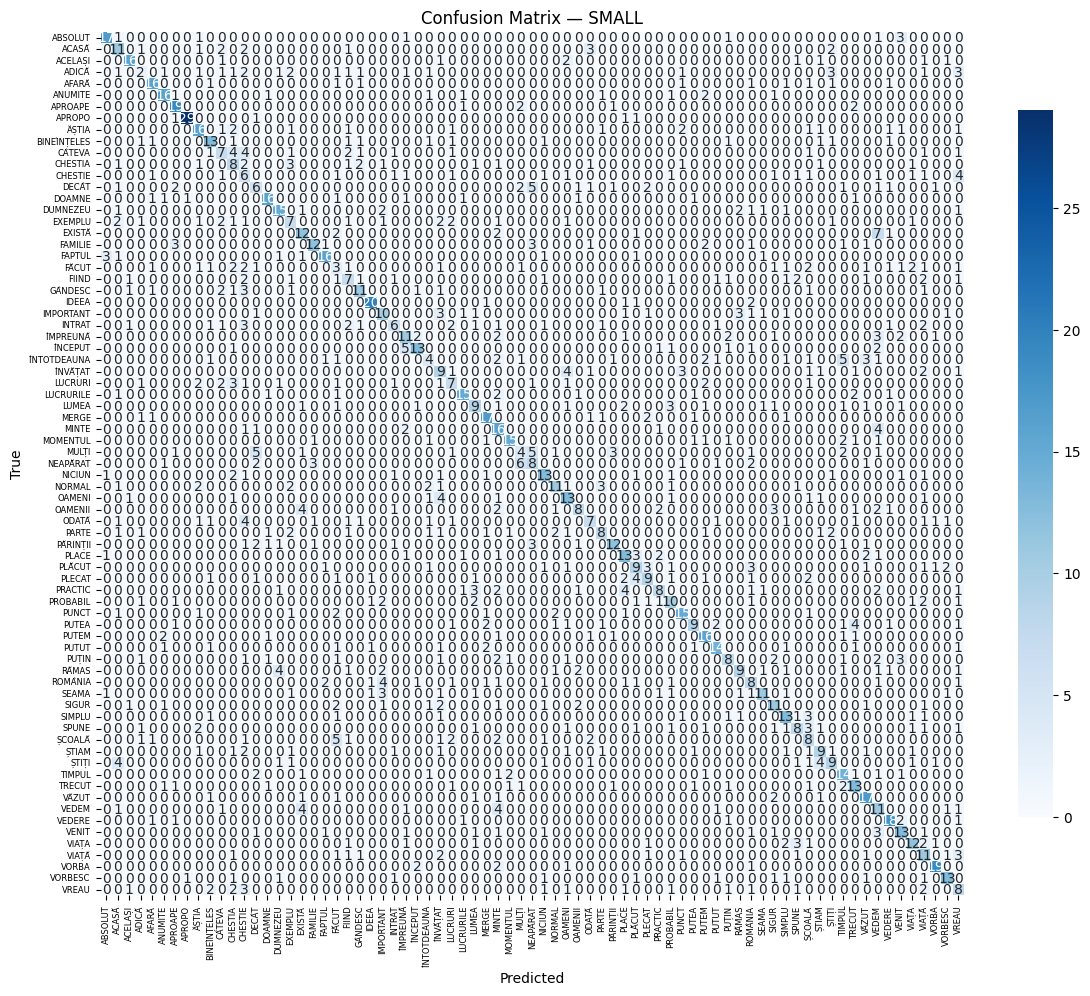

               precision    recall  f1-score   support

      ABSOLUT       0.74      0.68      0.71        25
       ACASĂ       0.38      0.48      0.42        23
     ACELAȘI       0.73      0.67      0.70        24
       ADICĂ       0.17      0.08      0.11        25
       AFARĂ       0.67      0.64      0.65        25
      ANUMITE       0.67      0.64      0.65        25
      APROAPE       0.61      0.76      0.68        25
       APROPO       0.94      0.88      0.91        33
      ĂȘTIA       0.52      0.53      0.52        30
BINEÎNȚELES       0.52      0.52      0.52        25
      CÂTEVA       0.33      0.28      0.30        25
      CHESTIA       0.25      0.32      0.28        25
      CHESTIE       0.14      0.24      0.18        25
       DECÂT       0.26      0.24      0.25        25
       DOAMNE       0.70      0.64      0.67        25
     DUMNEZEU       0.58      0.60      0.59        25
      EXEMPLU       0.29      0.28      0.29        25
      EXI

In [22]:
eval_variant("small")

[train_m] 22466 samples, 75 classes.
[test_m] 1873 samples, 75 classes.


=== MEDIUM | T=40 | loss 1.9186 | top-1 53.39% | top-5 80.94% ===


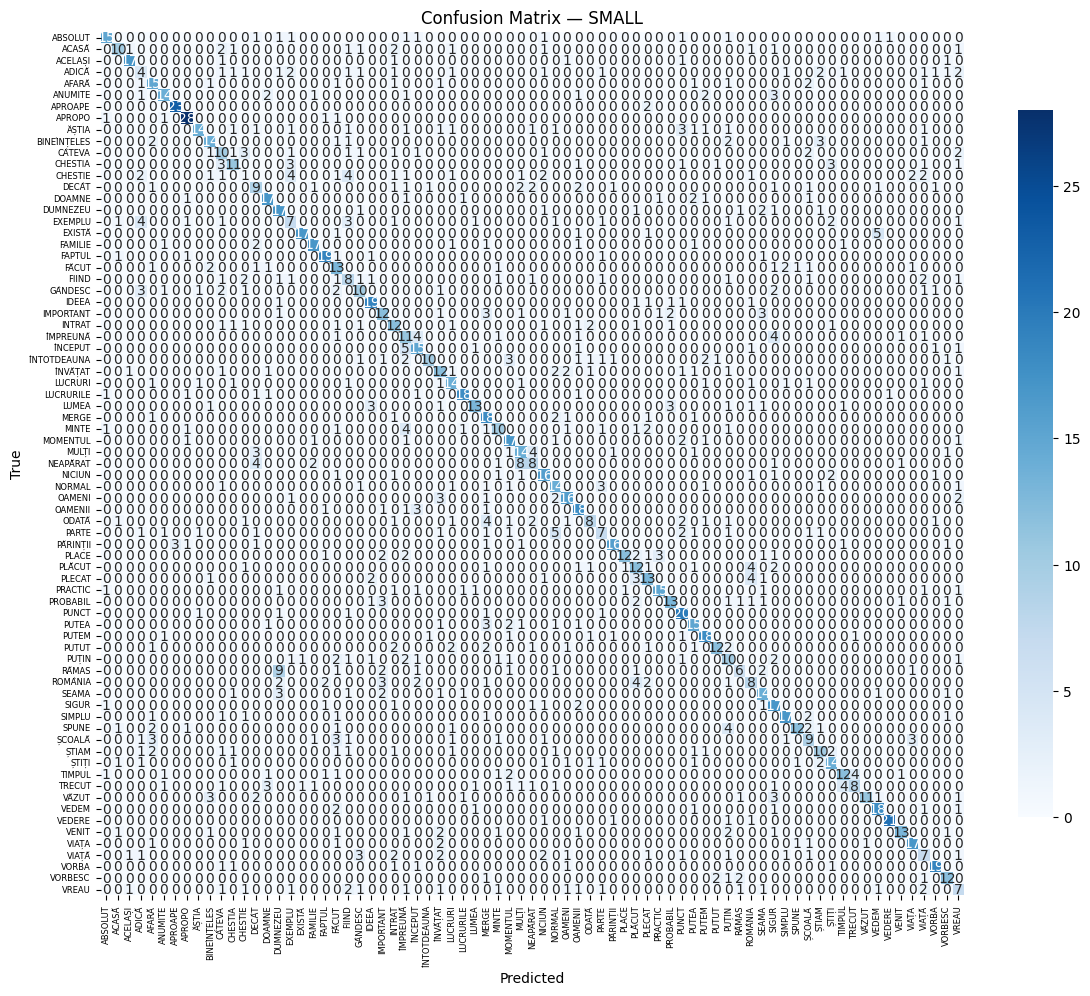

               precision    recall  f1-score   support

      ABSOLUT       0.71      0.60      0.65        25
       ACASĂ       0.62      0.43      0.51        23
     ACELAȘI       0.81      0.77      0.79        22
       ADICĂ       0.20      0.16      0.18        25
       AFARĂ       0.48      0.60      0.54        25
      ANUMITE       0.67      0.56      0.61        25
      APROAPE       0.88      0.92      0.90        25
       APROPO       0.78      0.88      0.82        32
      ĂȘTIA       0.78      0.47      0.58        30
BINEÎNȚELES       0.56      0.56      0.56        25
      CÂTEVA       0.33      0.40      0.36        25
      CHESTIA       0.52      0.44      0.48        25
      CHESTIE       0.07      0.04      0.05        25
       DECÂT       0.35      0.36      0.35        25
       DOAMNE       0.63      0.68      0.65        25
     DUMNEZEU       0.45      0.68      0.54        25
      EXEMPLU       0.30      0.28      0.29        25
      EXI

In [23]:
eval_variant("medium")

[train_l] 22489 samples, 75 classes.
[test_l] 1878 samples, 75 classes.


=== LARGE | T=60 | loss 2.0453 | top-1 47.34% | top-5 76.84% ===


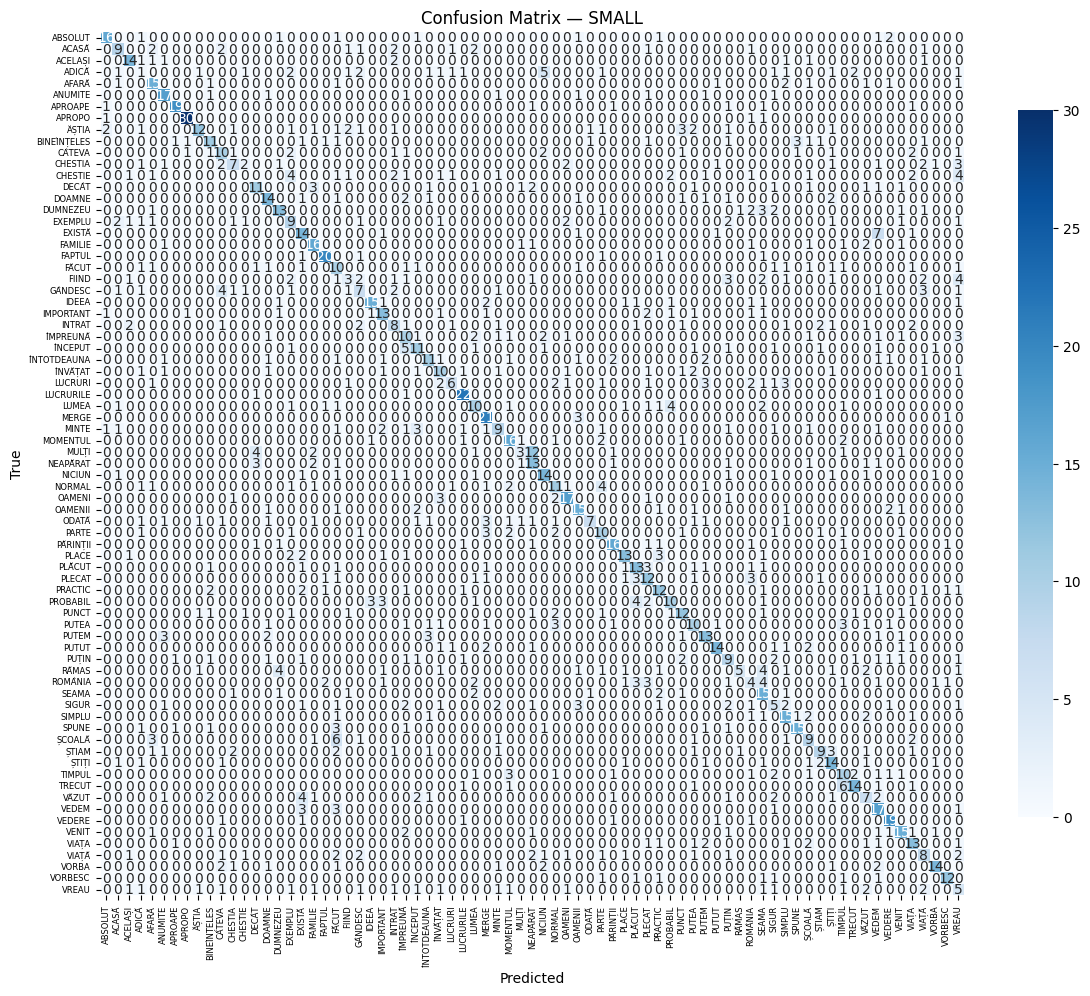

               precision    recall  f1-score   support

      ABSOLUT       0.73      0.64      0.68        25
       ACASĂ       0.50      0.39      0.44        23
     ACELAȘI       0.64      0.64      0.64        22
       ADICĂ       0.07      0.04      0.05        25
       AFARĂ       0.52      0.60      0.56        25
      ANUMITE       0.59      0.68      0.63        25
      APROAPE       0.83      0.76      0.79        25
       APROPO       0.91      0.91      0.91        33
      ĂȘTIA       0.71      0.38      0.49        32
BINEÎNȚELES       0.48      0.44      0.46        25
      CÂTEVA       0.38      0.40      0.39        25
      CHESTIA       0.44      0.28      0.34        25
      CHESTIE       0.00      0.00      0.00        25
       DECÂT       0.52      0.44      0.48        25
       DOAMNE       0.54      0.56      0.55        25
     DUMNEZEU       0.57      0.52      0.54        25
      EXEMPLU       0.31      0.36      0.33        25
      EXI

In [24]:
eval_variant("large")

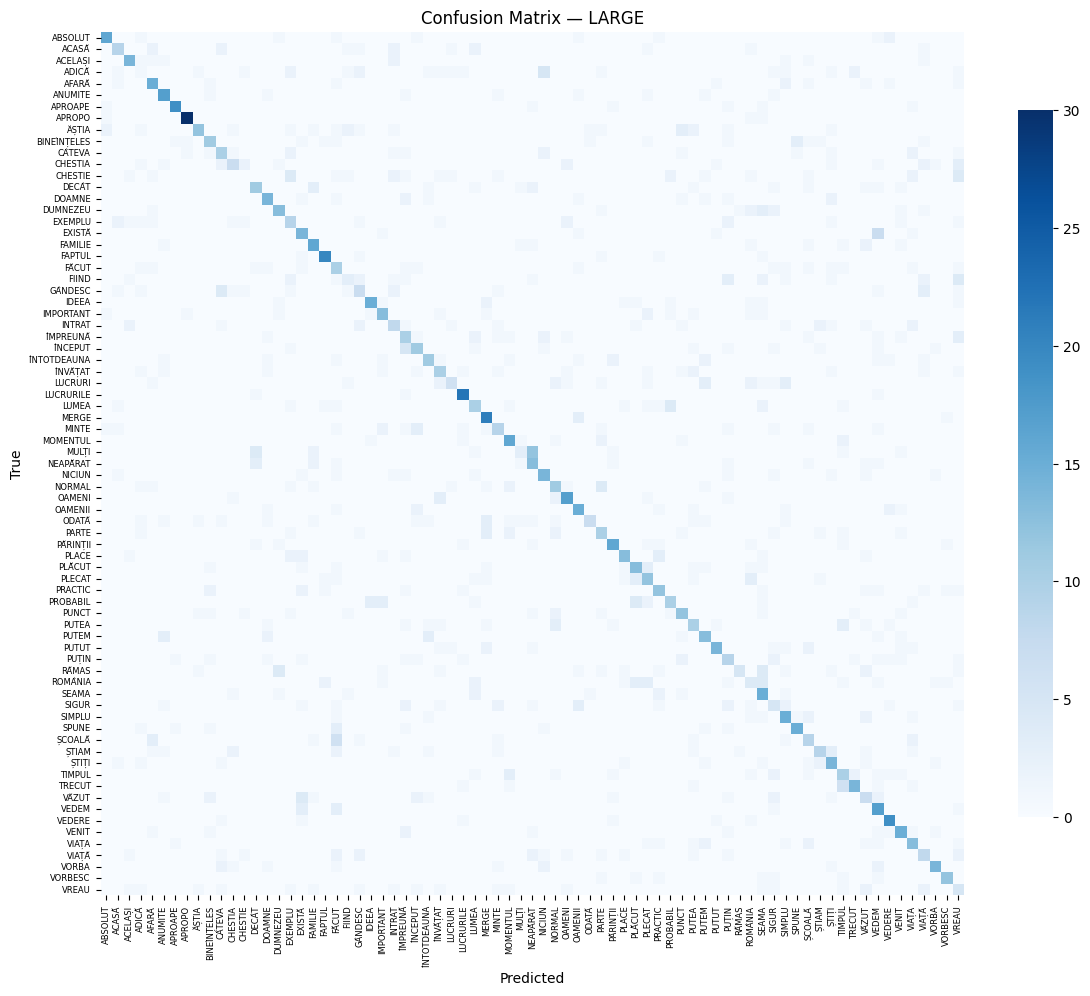

               precision    recall  f1-score   support

      ABSOLUT       0.73      0.64      0.68        25
       ACASĂ       0.50      0.39      0.44        23
     ACELAȘI       0.64      0.64      0.64        22
       ADICĂ       0.07      0.04      0.05        25
       AFARĂ       0.52      0.60      0.56        25
      ANUMITE       0.59      0.68      0.63        25
      APROAPE       0.83      0.76      0.79        25
       APROPO       0.91      0.91      0.91        33
      ĂȘTIA       0.71      0.38      0.49        32
BINEÎNȚELES       0.48      0.44      0.46        25
      CÂTEVA       0.38      0.40      0.39        25
      CHESTIA       0.44      0.28      0.34        25
      CHESTIE       0.00      0.00      0.00        25
       DECÂT       0.52      0.44      0.48        25
       DOAMNE       0.54      0.56      0.55        25
     DUMNEZEU       0.57      0.52      0.54        25
      EXEMPLU       0.31      0.36      0.33        25
      EXI

In [ ]:
# =====================================================================
# Evaluate the best checkpoint on the test split and save artefacts
# =====================================================================
from pathlib import Path

import torch
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics import classification_report, confusion_matrix


@torch.no_grad()
def evaluate_confusion_matrix(model, loader, device, class_names, variant,
                              amp=True, annotate=None, save_path=None):
    """Run the model over `loader`, plot a confusion matrix, and return
    (labels, preds) as 1-D CPU tensors for downstream reporting."""
    model.eval()
    all_preds, all_labels = [], []

    for clips, word_bounds, labels in tqdm(loader, desc="Confusion matrix", leave=False):
        clips       = clips.to(device, non_blocking=True)
        word_bounds = word_bounds.to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, enabled=amp):
            logits = model(clips, word_bounds)

        all_preds.append(logits.argmax(1).cpu())
        all_labels.append(labels.cpu())

    all_preds  = torch.cat(all_preds)
    all_labels = torch.cat(all_labels)

    # Pin the label set so the matrix is always (C x C) and aligned with class_names,
    # even if some class never appears in preds or labels.
    n_classes = len(class_names)
    cm = confusion_matrix(all_labels, all_preds, labels=range(n_classes))

    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names,
                square=True, cbar_kws={"shrink": 0.8},  
                )
    plt.xticks(rotation=90, fontsize=6)
    plt.yticks(fontsize=6)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion Matrix — {variant.upper()}")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    return all_labels, all_preds


# --- Build the class list in the SAME order used during training ----------
# Training sorted uppercased folder names; mirror that exactly here.
dataset_dir = Path(r"E:\raw_videos")
class_names = sorted(d.name.upper() for d in dataset_dir.iterdir() if d.is_dir())

# --- Run evaluation -------------------------------------------------------
all_labels, all_preds = evaluate_confusion_matrix(
    model, test_loader, device, class_names, variant=VARIANT, amp=amp,
)

print(classification_report(all_labels, all_preds, target_names=class_names))

In [19]:
# =====================================================================
# Evaluate the best checkpoint on the test split and save artefacts
# =====================================================================
from pathlib import Path

import torch
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics import classification_report, confusion_matrix


@torch.no_grad()
def evaluate_confusion_matrix(model, loader, device, class_names, variant,
                              amp=True, annotate=None, save_path=None):
    """Run the model over `loader`, plot a confusion matrix, and return
    (labels, preds) as 1-D CPU tensors for downstream reporting."""
    model.eval()
    all_preds, all_labels = [], []

    for clips, word_bounds, labels in tqdm(loader, desc="Confusion matrix", leave=False):
        clips       = clips.to(device, non_blocking=True)
        word_bounds = word_bounds.to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, enabled=amp):
            logits = model(clips, word_bounds)

        all_preds.append(logits.argmax(1).cpu())
        all_labels.append(labels.cpu())

    all_preds  = torch.cat(all_preds)
    all_labels = torch.cat(all_labels)

    # Pin the label set so the matrix is always (C x C) and aligned with class_names,
    # even if some class never appears in preds or labels.
    n_classes = len(class_names)
    cm = confusion_matrix(all_labels, all_preds, labels=range(n_classes))

    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names,
                square=True, cbar_kws={"shrink": 0.8},  
                )
    plt.xticks(rotation=90, fontsize=6)
    plt.yticks(fontsize=6)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion Matrix — {variant.upper()}")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    return all_labels, all_preds


# # --- Build the class list in the SAME order used during training ----------
# # Training sorted uppercased folder names; mirror that exactly here.
# dataset_dir = Path(r"E:\raw_videos")
# class_names = sorted(d.name.upper() for d in dataset_dir.iterdir() if d.is_dir())

# # --- Run evaluation -------------------------------------------------------
# all_labels, all_preds = evaluate_confusion_matrix(
#     model, test_loader, device, class_names, variant=VARIANT, amp=amp,
# )

# print(classification_report(all_labels, all_preds, target_names=class_names))

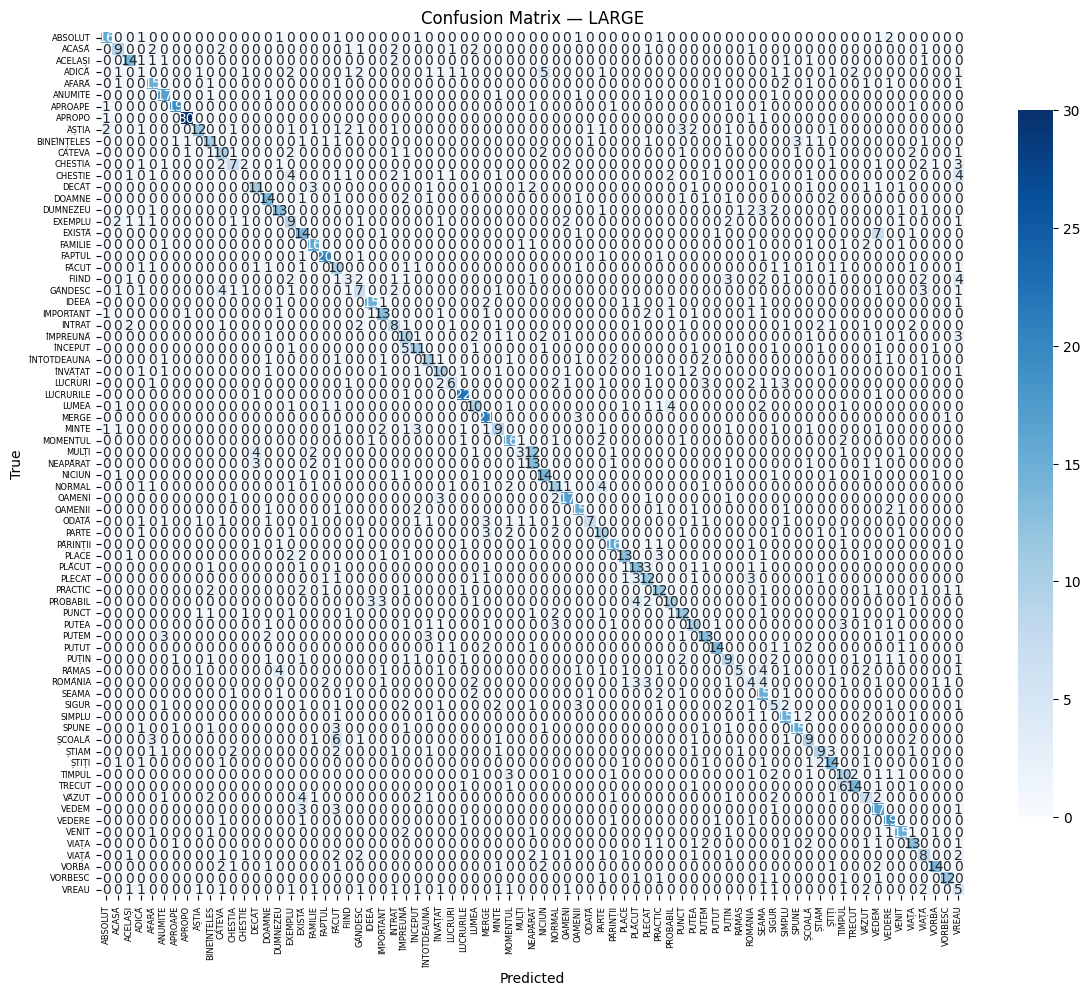

               precision    recall  f1-score   support

      ABSOLUT       0.73      0.64      0.68        25
       ACASĂ       0.50      0.39      0.44        23
     ACELAȘI       0.64      0.64      0.64        22
       ADICĂ       0.07      0.04      0.05        25
       AFARĂ       0.52      0.60      0.56        25
      ANUMITE       0.59      0.68      0.63        25
      APROAPE       0.83      0.76      0.79        25
       APROPO       0.91      0.91      0.91        33
      ĂȘTIA       0.71      0.38      0.49        32
BINEÎNȚELES       0.48      0.44      0.46        25
      CÂTEVA       0.38      0.40      0.39        25
      CHESTIA       0.44      0.28      0.34        25
      CHESTIE       0.00      0.00      0.00        25
       DECÂT       0.52      0.44      0.48        25
       DOAMNE       0.54      0.56      0.55        25
     DUMNEZEU       0.57      0.52      0.54        25
      EXEMPLU       0.31      0.36      0.33        25
      EXI

In [38]:
# --- Run evaluation -------------------------------------------------------
all_labels, all_preds = evaluate_confusion_matrix(
    model, test_loader, device, class_names, variant=VARIANT, amp=amp,
)

print(classification_report(all_labels, all_preds, target_names=class_names))